#### EDA on movies_popular_pre2010 dataset

load data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

popmov = pd.read_csv("../../data/movies_popular_pre2010.csv")

popmov.head()

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
0,6,"10,000 B.C.",A young outcast from a primitive tribe is forc...,PG-13,"Action & Adventure, Classics, Drama",Roland Emmerich,2008-03-07,2008-06-24,109.0,8,148,37.0,411087.0,2008
1,51,Aliens,"Big-budget special effects, swiftly paced acti...",R,"Action & Adventure, Horror, Science Fiction & ...",James Cameron,1986-07-18,1999-06-01,138.0,99,72,94.0,429158.0,1986
2,85,The Happening,"The Happening' is a lightning-paced, heart-pou...",R,"Drama, Mystery & Suspense, Science Fiction & F...",M. Night Shyamalan,2008-06-11,2008-10-07,90.0,18,179,24.0,370131.0,2008
3,144,The Box,Norma and Arthur Lewis are a suburban couple w...,PG-13,"Horror, Mystery & Suspense, Science Fiction & ...",Richard Kelly,2009-11-06,2010-02-23,116.0,44,155,24.0,359067.0,2009
4,94,Disney's A Christmas Carol,Ebenezer Scrooge begins the Christmas holiday ...,PG,"Animation, Drama, Kids & Family, Science Ficti...",Robert Zemeckis,2009-11-06,2010-11-16,96.0,53,197,58.0,776113.0,2009


#### Movie Rating Analysis

What percent of movies fall under each type of rating (R, PG-13, etc.)?

In [4]:
# Check for missing values in the rating column
popmov['rating'].isna().sum()

0

In [6]:
# counts and percentages by rating
rating_counts = popmov["rating"].value_counts().sort_index()
rating_percent = rating_counts / len(popmov) * 100

rating_summary = pd.DataFrame({
    "count": rating_counts,
    "percent": rating_percent.round(1)
})

rating_summary

,count,percent
rating,,
G,41,4.9
PG,170,20.2
PG-13,368,43.7
R,264,31.3


Among popular pre-2010 movies, nearly half are PG-13 (about 44%) and about a third are R-rated (31%), while PG makes up around 20% and G only about 5%. So this “popular” subset is heavily skewed toward teen and adult audiences, with relatively few purely family-oriented (G) titles.

Create a visualization that shows for each rating (R, PG-13, etc.), the average critic rating and the average audience rating.

In [7]:
# average critic and audience rating for each rating category
rating_means = (
    popmov.groupby("rating")[["critic_rating", "audience_rating"]]
      .mean()
      .sort_index()
)

rating_means

,critic_rating,audience_rating
rating,,
G,73.512195,73.195122
PG,59.652941,65.870588
PG-13,49.926630,63.086957
R,61.121212,70.821970


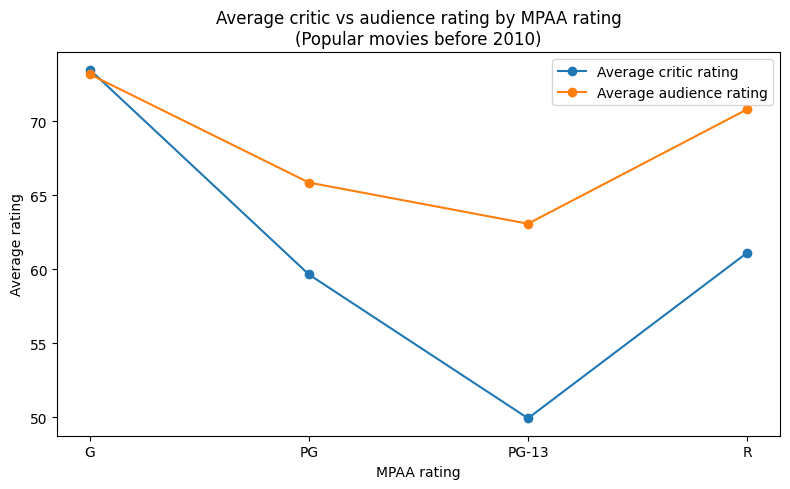

In [9]:
plt.figure(figsize=(8, 5))

x = range(len(rating_means))
plt.plot(x, rating_means["critic_rating"], marker="o", label="Average critic rating")
plt.plot(x, rating_means["audience_rating"], marker="o", label="Average audience rating")

plt.xticks(x, rating_means.index)
plt.xlabel("MPAA rating")
plt.ylabel("Average rating")
plt.title("Average critic vs audience rating by MPAA rating\n(Popular movies before 2010)")
plt.legend()
plt.tight_layout()
plt.show()

For popular pre-2010 movies, G-rated films have the highest average critic and audience scores among the four rating categories. PG and especially PG-13 movies tend to have lower average critic scores than G and R movies. Across all categories, audience ratings are consistently higher than critic ratings, with the biggest differences for PG-13 and R, suggesting that viewers are generally more enthusiastic about these films than critics are.